In [44]:
import numpy as np 
import cv2 
import matplotlib.pyplot as plt 
from pathlib import Path
from skimage import data, color, exposure, transform, img_as_ubyte
from PIL import Image
%matplotlib inline

In [63]:
#img_rgb = data.astronaut()
adress = Path(r"..\img\img1.JPEG")
img_rgb = cv2.cvtColor(cv2.imread(adress), cv2.COLOR_BGR2RGB)
#img_rgb = cv2.imread(adress)
print("Shap", img_rgb.shape)
print("dtype", img_rgb.dtype)
print("min/max", img_rgb.min(), img_rgb.max())

Shap (1600, 1200, 3)
dtype uint8
min/max 0 255


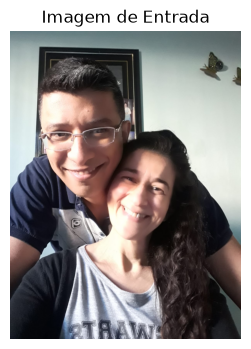

In [64]:
plt.figure(figsize=(4, 4))
plt.imshow(img_rgb)
plt.title("Imagem de Entrada")
plt.axis("off")
plt.show()

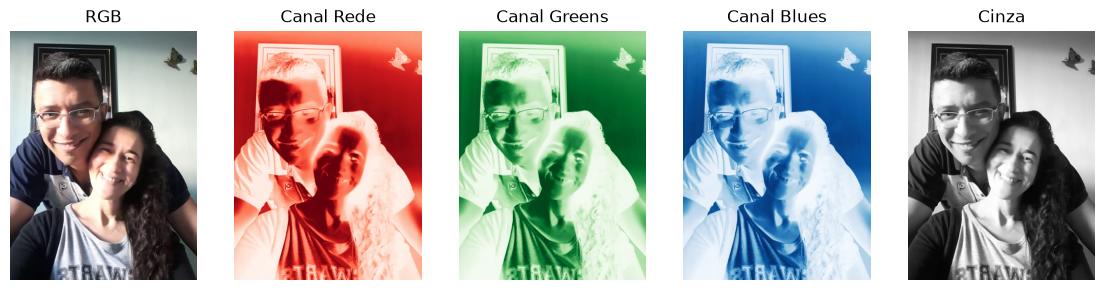

In [ ]:
red, green, blue = img_rgb[:, :, 0], img_rgb[:, :, 1], img_rgb[:, :, 2]

img_gray = color.rgb2gray(img_rgb) # -> Fórmula da Luminância
img_gray_u8 = (img_gray * 255).astype(np.uint8)

fig, ax = plt.subplots(1, 6, figsize=(14, 4))
ax[0].imshow(img_rgb); ax[0].set_title("RGB")
ax[1].imshow(red, cmap='Reds'); ax[1].set_title("Canal Rede")
ax[2].imshow(green, cmap='Greens'); ax[2].set_title("Canal Greens")
ax[3].imshow(blue, cmap='Blues'); ax[3].set_title("Canal Blues")
ax[4].imshow(img_gray_u8, cmap='gray'); ax[4].set_title("Cinza")

for a in ax: a.axis("off")
plt.show()

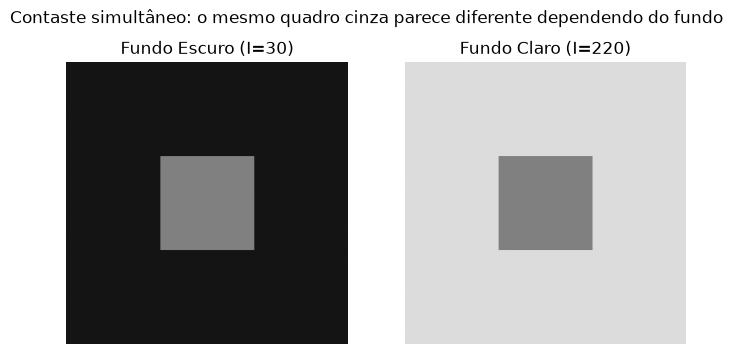

In [55]:
obj = np.full((80, 80), 128, dtype=np.uint8)
backg_dark = np.full((240, 240), 20, dtype=np.uint8)
backg_light = np.full((240,240), 220, dtype=np.uint8)

backg_dark[80:160, 80:160] = obj
backg_light[80:160, 80:160] = obj

fig, ax = plt.subplots(1, 2, figsize=(8, 4))
for a, f, t in zip(ax, [backg_dark, backg_light], ["Fundo Escuro (I=30)","Fundo Claro (I=220)" ]):
    a.imshow(f,cmap='gray', vmin=0, vmax=255)
    a.set_title(t); a.axis("off")
plt.suptitle("Contaste simultâneo: o mesmo quadro cinza parece diferente dependendo do fundo")
plt.show()

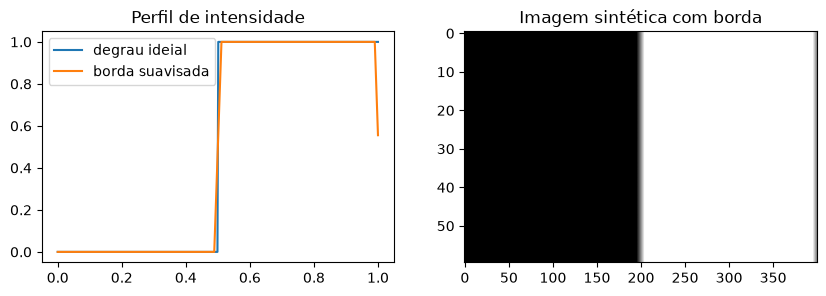

In [56]:
x = np.linspace(0, 1, 400)
degrau = (x > 0.5).astype(float)
suave = np.convolve(degrau, np.ones(9)/9, mode="same")
fig, ax = plt.subplots(1, 2, figsize=(10, 3))
ax[0].plot(x, degrau, label="degrau ideial")
ax[0].plot(x, suave, label="borda suavisada")
ax[0].legend(); ax[0].set_title("Perfil de intensidade")
ax[1].imshow(np.tile(suave, (60, 1)), cmap="gray", aspect="auto")
ax[1].set_title("Imagem sintética com borda")
plt.show()

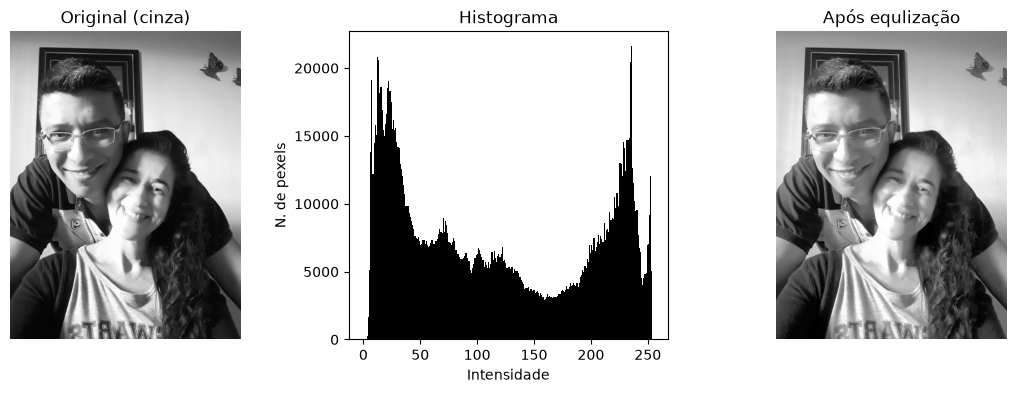

In [57]:
fig, ax = plt.subplots(1, 3, figsize=(14, 4))
ax[0].imshow(img_gray_u8, cmap="gray"); ax[0].set_title("Original (cinza)"); ax[0].axis("off")
ax[1].hist(img_gray_u8.ravel(), bins=256, range=(0, 255), color="k")
ax[1].set_title("Histograma"); ax[1].set_xlabel("Intensidade"); ax[1].set_ylabel("N. de pexels")

eq = exposure.equalize_hist(img_gray_u8)
ax[2].imshow(eq, cmap="gray"); ax[2].set_title("Após equlização"); ax[2].axis("off")
plt.show()

In [ ]:
h = 6.626e-34
c = 3.0e8
lam_nm = np.linspace(380, 750, 200)
lam_m = lam_nm * 1e-9
e = h * c / lam_m

fig, ax = plt.subplots(figsize=(8, 3))
ax.plot(lam_nm, e, color="purple")
ax.axvspan(380, 450, color="violet", alpha=.2, label="Violeta")
ax.axvspan(450, 495, color="blue", alpha=.15, label="Azul")
ax.axvspan(495, 570, color="green", alpha=.15, label="Verde")
ax.axvspan(570, 590, color="yellow", alpha=.15, label="Amarelo")
ax.axvspan(590, 620, color="orange", alpha=.15, label="Laranja")
ax.axvspan(620, 750, color="red", alpha=.15, label="Vermelho")
ax.set_xlabel("Comprimento de onda (nm)")
ax.set_ylabel("Energia de fóton E (J)")
ax.legend(fontsize=7, ncol=3)
plt.show()

In [ ]:
img_rgb = data.camera()
img_f = img_rgb.astype(np.float32) / 255.0

In [ ]:
r = np.zeros((200, 300))
r[:, 100] = 0.05
r[:, 100:200] = 0.80
r[:, 200:] = 0.93

i_sol = 90000.0
i_nublado = 10000.0

f_sol = i_sol * r
f_nublado = i_nublado * r

def norm255(a):
    a = (a - a.min()) / (a.max() - a.min())
    return (a * 255).astype(np.uint8)

fig, ax = plt.subplots(1, 2, figsize=(10, 4))

for a, f, t in zip(ax, [f_sol, f_nublado], ["i = 90.000 luz, i = 10.000 nublado"]):
    a.imshow(norm255(f), cmap="gray", aspect="auto")
    a.set_title(t); a.axis("off")

plt.suptitle("f = i * r: - o contraste vem da reflexão r e da intensidade i da luz incidente")
plt.show()

In [ ]:
def amostra(img, passos=(1, 4, 16, 64)):
    fig, ax = plt.subplots(1, len(passos), figsize=(14, 4))

    for a, p in zip(ax, passos):
        small = transform.downscale_local_mean(img_f,(p, p))
        a.imshow(small, cmap="gray", interpolation="nearest")
        a.set_title(f"Passo {p}px\n{small.shape[1]}x{small.shape[0]}")
        a.axis("off")
    plt.suptitle("Amostragem: reduzir a grade => pixelização")
    plt.show()

amostra(img_f)

In [ ]:
def quantize(img_f, k):
    L = 2**k
    q = np.floor(img_f * (L - 1) + 0.5) / (L - 1)
    return q

ks = [8, 6, 4, 3, 2, 1]
fig, ax = plt.subplots(2, 3, figsize=(12, 7))

for a, k in zip(ax.ravel(), ks):
    a.imshow(quantize(img_f, k), cmap="gray", vmin=0, vmax=1)
    a.set_title(f"k={k} -> L={2**k} níveis")
    a.axis("off")
plt.suptitle("Quantização: de 256 a 2 níveis  -> falsos contornos (banding)")
plt.tight_layout()
plt.show()

In [ ]:
def digitalize(img_f, passo, k):
    small = transform.downscale_local_mean(img_f, (passo, passo))
    return quantize(small, k)

combos = [(1, 8, "Original"), 
          (4, 4, "Pouca amostra, \n4bits"), 
          (16, 2, "Muita redução, \n2bits"), 
          (8, 3, "Meio termo")]

fig, ax = plt.subplots(1, 4, figsize=(14, 6))

for a, (p, k, t) in zip(ax, combos):
    a.imshow(digitalize(img_f, p, k), cmap="gray", vmin=0, vmax=1, interpolation="nearest")
    a.set_title(f"{t}\npasso={p}, k={k}")
    a.axis("off")
plt.suptitle("Digitalização: amostragem + quantização")
plt.show()

In [ ]:
def simula_dpi(img, dpi_alvo, dpi_ref=1250, polegadas=2.95):
    alvo_px = int(dpi_alvo * polegadas)
    return transform.resize(img, (alvo_px, alvo_px),anti_aliasing=True, preserve_range=True)

dpi_list = [1250, 300, 150, 75]
fig, ax = plt.subplots(1, 4, figsize=(14, 4))

for a, d in zip(ax, dpi_list):
    im = simula_dpi(img_f, d)
    a.imshow(im, cmap="gray", vmin=0, vmax=1)
    a.set_title(f"{d} dpi\n{im.shape[1]}x{im.shape[0]}px")
    a.axis("off")

plt.suptitle("Mesmo cena, mesma área física: menos dpi => menos pixels => pixelização")
plt.show()

In [ ]:
N = np.linspace(64, 1024, 300)

fig, ax = plt.subplots(figsize=(8, 4.5))

for C, rot in [(2e4, "Imagem simples"),(5e4, "Imagem média"), (1.2e5, "Imagem rica")]:
    k = 2 * np.log2(C / N)
    ax.plot(N, k, label=rot)

ax.set_xlabel("N (lado da imagem, pixels)")
ax.set_ylabel("k (bits por pixel)")
ax.set_title("Curvas de isopreferência: reduzir N => aumentar k")
ax.grid(True, alpha=.3)
ax.legend()
plt.show()

In [ ]:
Ns = np.array([32, 64, 128, 256, 512, 1024, 2048, 4096,8192])
Ks = np.arange(1, 9)

B = Ns[:, None]**2 * Ks[None, :]

print("N\\K " + " ".join([f"{k:>10}" for k in Ks]))
for i, n in enumerate(Ns):
    print(f"end={n:>4} " + " ".join([f"{v:>10d}" for v in B[i]]))

print("\nN=512, k=1 ->, 512**2*1 ")
print("N=512, k=8  ->", 512**2*8, "=", 512**2*8/8/1024/1024, "MiB")
print("N=8192, k=8 ->", 8192**2*8, "bits =", 8192**2*8/8/1024/1024, "MiB")

In [ ]:
def varredura_linha(img, passo=1):
    out = np.zeros_like(img)
    for y in range(0, img.shape[0], passo):
        out[y:y+passo, :] = img[y:y+passo, :]
    return out

def varredura_ponto(img, passo=4):
    out = np.zeros_like(img)
    out[::passo, ::passo] = img[::passo, ::passo]
    return out 

fig, ax = plt.subplots(1, 3, figsize=(13, 6))
ax[0].imshow(img_f, cmap="gray"); ax[0].set_title("original"); ax[0].axis("off")
ax[1].imshow(varredura_linha(img_f, passo=16), cmap="gray")
ax[1].set_title("sensor de linha\n(1 fileira por passo)"); ax[1].axis("off")
ax[2].imshow(varredura_ponto(img_f, passo=16), cmap="gray")
ax[2].set_title("sensor simples\n(1 ponto por passo em x,y)"); ax[2].axis("off")
plt.suptitle("O que cada sensor capta por vez define o limite de amostragem")
plt.show() 

In [ ]:
import os
from pathlib import Path

caminho = Path(r"C:\TI\Python\Visão Computacional\img\img1.JPEG")

print("Pasta existe:", caminho.parent.exists())
print("Arquivo existe:", caminho.is_file())

if caminho.parent.exists():
    print("Arquivos na pasta:", [arquivo.name for arquivo in caminho.parent.iterdir()])

img_bgr = cv2.imread(str(caminho))
print("OpenCV carregou a imagem:", img_bgr is not None)